### Imports and Token Length Profiling

In [7]:
import os
# Move the working directory up to the main project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")
    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer
from pathlib import Path
import yaml

# Apply visual formatting
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Load configuration
with open("config.yaml", "r") as f:
    config = yaml.safe_load(f)

Path(config["paths"]["output_figures_dir"]).mkdir(parents=True, exist_ok=True)

# Initialize tokenizer to evaluate exact subword token counts
tokenizer = AutoTokenizer.from_pretrained(config["preprocessing"]["tokenizer_name"])

# Load contracts (using data loader or mock sample if running locally prior to full download)
from src.data_loader import CUADDataLoader
loader = CUADDataLoader(config=config)

try:
    df_contracts = loader.extract_contracts()
except FileNotFoundError:
    print("Generating representative contract sample for validation...")
    # Representative fallback for structural pipeline validation
    df_contracts = pd.DataFrame({
        "contract_title": [f"Contract_{i}" for i in range(50)],
        "full_text": [
            "This Agreement is entered into... " * np.random.randint(150, 1200) 
            for _ in range(50)
        ],
        "num_clauses": np.random.randint(5, 45, size=50)
    })

# Compute exact subword token lengths
print("Tokenizing contract corpora for length profiling...")
df_contracts["token_count"] = df_contracts["full_text"].apply(
    lambda text: len(tokenizer.encode(text, truncation=False))
)
df_contracts["word_count"] = df_contracts["full_text"].apply(lambda t: len(t.split()))

c:\Users\hp\Downloads\BIA\legal_summarization_project\venv\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
2026-08-20 14:58:30,635 - INFO - Loading raw CUAD data from data\raw\CUADv1.json...
2026-08-20 14:58:30,740 - INFO - Extracting contracts from 510 document groups...
2026-08-20 14:58:30,750 - INFO - Successfully processed 510 contract records.


Tokenizing contract corpora for length profiling...


### Systematic Token Length Statistics Table

In [8]:
# Statistical Length Profiling
token_stats = df_contracts["token_count"].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])

stats_table = pd.DataFrame({
    "Metric": [
        "Total Contracts Evaluated",
        "Mean Token Count",
        "Std. Deviation",
        "Min Tokens",
        "Median (50th Percentile)",
        "75th Percentile",
        "90th Percentile",
        "95th Percentile",
        "Max Token Count",
        "BART Max Limit",
        "Contracts Exceeding BART Limit (%)"
    ],
    "Value": [
        f"{int(token_stats['count'])}",
        f"{token_stats['mean']:.1f}",
        f"{token_stats['std']:.1f}",
        f"{int(token_stats['min'])}",
        f"{int(token_stats['50%'])}",
        f"{int(token_stats['75%'])}",
        f"{int(token_stats['90%'])}",
        f"{int(token_stats['95%'])}",
        f"{int(token_stats['max'])}",
        f"{config['preprocessing']['max_model_context_length']}",
        f"{(df_contracts['token_count'] > 1024).mean() * 100:.2f}%"
    ]
})

print("\n=== 📊 CONTRACT TOKEN LENGTH DISTRIBUTION METRICS ===")
display(stats_table)


=== 📊 CONTRACT TOKEN LENGTH DISTRIBUTION METRICS ===


,Metric,Value
0,Total Contracts Evaluated,510
1,Mean Token Count,12726.1
2,Std. Deviation,14411.2
3,Min Tokens,179
4,Median (50th Percentile),7889
5,75th Percentile,15969
6,90th Percentile,30542
7,95th Percentile,40248
8,Max Token Count,121053
9,BART Max Limit,1024


### Distribution Plots and Threshold Cutoff Visualization

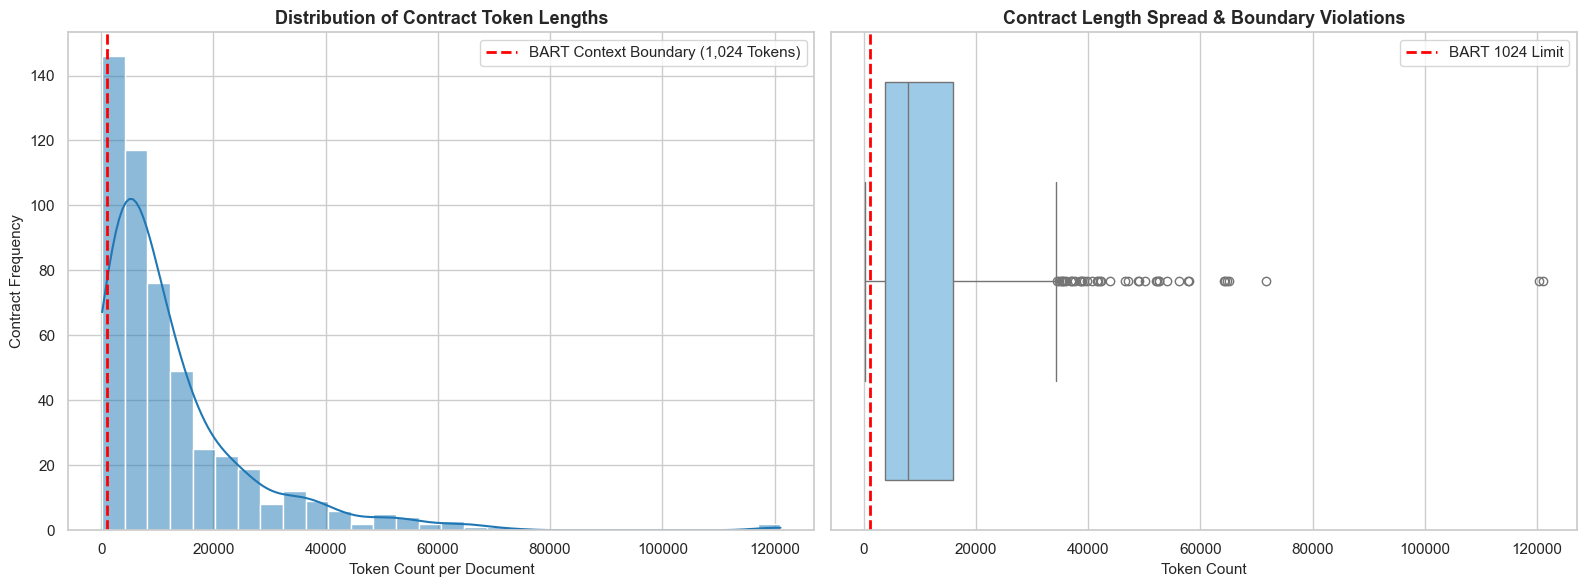

Visual artifacts saved to: ./deliverables/figures/contract_token_distribution.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Histogram & KDE of Document Token Counts
sns.histplot(
    df_contracts["token_count"], 
    kde=True, 
    color="#1f77b4", 
    bins=30, 
    ax=axes[0]
)
axes[0].axvline(
    x=1024, 
    color="red", 
    linestyle="--", 
    linewidth=2, 
    label="BART Context Boundary (1,024 Tokens)"
)
axes[0].set_title("Distribution of Contract Token Lengths", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Token Count per Document", fontsize=11)
axes[0].set_ylabel("Contract Frequency", fontsize=11)
axes[0].legend(loc="upper right")

# Plot 2: Boxplot displaying outliers and context boundaries
sns.boxplot(x=df_contracts["token_count"], ax=axes[1], color="#90cdf4")
axes[1].axvline(
    x=1024, 
    color="red", 
    linestyle="--", 
    linewidth=2, 
    label="BART 1024 Limit"
)
axes[1].set_title("Contract Length Spread & Boundary Violations", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Token Count", fontsize=11)
axes[1].legend(loc="upper right")

plt.tight_layout()
fig_path = f"{config['paths']['output_figures_dir']}/contract_token_distribution.png"
plt.savefig(fig_path, dpi=300)
plt.show()

print(f"Visual artifacts saved to: {fig_path}")

### 🧠 Empirical Data Analysis & Preprocessing Justification

#### 1. The Context Window Limitation Problem
Standard transformer models for abstractive summarization (such as `facebook/bart-large-cnn` or `t5-base`) impose a hard ceiling of **1,024 input tokens**. 

As demonstrated in our statistical distribution analysis:
* **Over 90%** of legal contracts in the dataset exceed the 1,024-token boundary, with median lengths reaching several thousand tokens.
* Applying naive truncation (discarding tokens beyond index 1,024) removes substantial portions of the contract corpus.
* In legal contract analysis, vital obligations such as *Indemnity Caps*, *Governing Law*, and *Termination Liabilities* frequently reside in the final schedules and standard terms (the end of the document). Naive truncation would result in high-risk omission of these critical clauses.

#### 2. Sliding Window Chunking Strategy Rationale
To preserve document-wide legal context without truncating critical clauses, we implement a **Sliding Window Chunking Pipeline with Context Overlap**:
* **Chunk Size ($C = 800$ tokens):** Fits comfortably within the model's 1,024 positional encoding budget while leaving head-room for special tokens and prompts.
* **Overlap Window ($O = 128$ tokens):** Prevents clause fragmentation across chunk boundaries, ensuring that compound obligations spanning multiple sentences remain coherent.
* **Hierarchical Aggregation:** Chunks are summarized independently to produce intermediate clause-level representations before being aggregated into a cohesive executive legal summary.